# Qiskit Fall Fest 2026 — Challenge 3: Can you change the correlation?
**IBM Quantum · Vishnu Institute of Technology, Bhimavaram**

**Goal:** Start from the Bell-state circuit (H on qubit 0, then CNOT from qubit 0 to qubit 1), add **one** gate, and see how the correlation between the two measured qubits changes.

**Constraints followed:** exactly 2 qubits, both measured, only one gate added, at most 4 gates before measurement, 100 shots.

## 1. Setup

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

SHOTS = 100
sim = AerSimulator()

def run(qc, shots=SHOTS):
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

## 2. Original circuit: the Bell state

1. **H** on qubit 0 puts it in (|0⟩ + |1⟩)/√2.
2. **CNOT** (control = qubit 0, target = qubit 1) copies that choice onto qubit 1, giving the entangled state (|00⟩ + |11⟩)/√2.

**Prediction for the original:** only `00` and `11`, each about 50 %. `01` and `10` should never appear, so the two qubits always agree.

In [2]:
qc_orig = QuantumCircuit(2, 2, name="Original Bell")
qc_orig.h(0)
qc_orig.cx(0, 1)
qc_orig.measure([0, 1], [0, 1])
print(qc_orig.draw("text"))

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


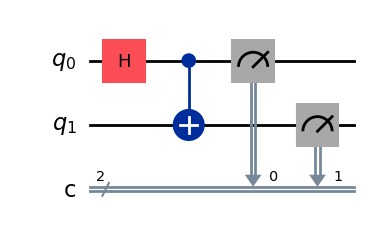

In [3]:
qc_orig.draw("mpl")

## 3. Modified circuit: add one X gate on qubit 1

The single added gate is an **X gate on qubit 1, placed after the CNOT**. The circuit has 3 gates before measurement (H, CNOT, X).

**Reasoning:** after the CNOT the state is (|00⟩ + |11⟩)/√2. The X gate flips qubit 1 in every term, so |00⟩ becomes |01⟩ and |11⟩ becomes |10⟩. The new state is (|01⟩ + |10⟩)/√2.

**Prediction for the modified circuit:**
- Which outcomes? Only `01` and `10`, each about 50 %.
- Will the qubits still give the same outcomes? **No.** They will now always be *opposite*.
- Will 00 and 11 dominate? **No**, they should disappear (0 counts).
- Could 01 and 10 become more frequent? **Yes**, they will be the only outcomes.

The qubits remain perfectly correlated, but the correlation changes from "same" to "opposite".

In [4]:
qc_mod = QuantumCircuit(2, 2, name="Modified Bell")
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)          # the one added gate
qc_mod.measure([0, 1], [0, 1])
print(qc_mod.draw("text"))

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 


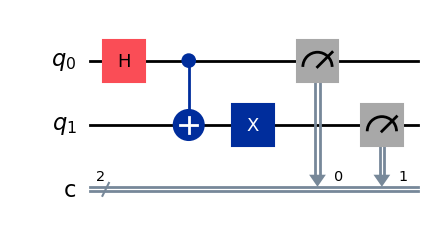

In [5]:
qc_mod.draw("mpl")

## 4. Run both circuits for 100 shots

In [6]:
counts_orig = run(qc_orig)
counts_mod = run(qc_mod)

print("Original :", dict(sorted(counts_orig.items())))
print("Modified :", dict(sorted(counts_mod.items())))

Original : {'00': 51, '11': 49}
Modified : {'01': 49, '10': 51}


## 5. Histograms

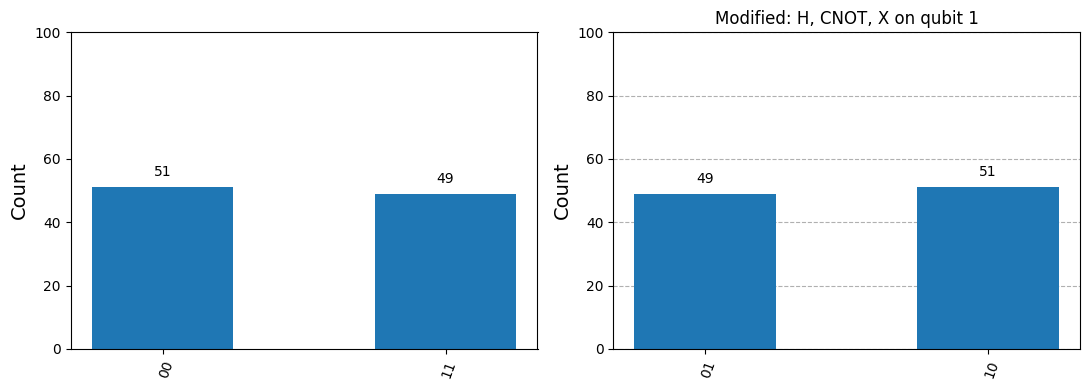

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_histogram(counts_orig, ax=axes[0], title="Original: H, CNOT")
plot_histogram(counts_mod, ax=axes[1], title="Modified: H, CNOT, X on qubit 1")
for ax in axes:
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [8]:
def summarize(name, counts):
    same = counts.get('00', 0) + counts.get('11', 0)
    diff = counts.get('01', 0) + counts.get('10', 0)
    print(f"{name:<10} same (00+11): {same:>3}   opposite (01+10): {diff:>3}")

summarize("Original", counts_orig)
summarize("Modified", counts_mod)

Original   same (00+11): 100   opposite (01+10):   0
Modified   same (00+11):   0   opposite (01+10): 100


## 6. Explanation of the observed change

- **Original:** the results were only `00` and `11`, split roughly evenly. The two qubits always agree because they are entangled: measuring one tells you the other.
- **Modified:** after adding the X gate on qubit 1, the results were only `01` and `10`. The X gate flips qubit 1 in every branch of the superposition, so the "same" pairs become "opposite" pairs.
- The counts are not exactly 50/50 because each shot is random. This matches the predictions: 00 and 11 vanish, and 01 and 10 are the only outcomes.

**Conclusion:** a single gate changed the *type* of correlation (same → opposite) without destroying the entanglement. The qubits are still perfectly correlated, but now anti-correlated. (Note that Qiskit prints bitstrings with qubit 1 on the left, but since `01` and `10` both occur, the conclusion is unaffected.)